# Systemy AI – Laboratorium 1
## Python, NumPy i pierwsze metryki klasyfikacji

**Cel:** przypomnienie Pythona w kontekście pracy z wynikami modeli, samodzielna implementacja metryk klasyfikacji binarnej i pierwszy mały eksperyment z hipotezą.

**Zasady**
- Zapisz kopię notatnika na swoim Dysku: *Plik → Zapisz kopię na Dysku*, nazwa `Lab1_AI_Nazwisko.ipynb`.
- Rozwiązania wpisuj w komórkach `# Twoje rozwiązanie`, odpowiedzi opisowe w komórkach *Twoja odpowiedź*.
- Komórki oznaczone `# TEST` sprawdzają rozwiązanie. Nie zmieniaj ich; jeśli zgłaszają błąd, popraw kod powyżej.
- Przed oddaniem: *Środowisko wykonawcze → Uruchom ponownie i uruchom wszystko*. Notatnik musi wykonać się od góry do dołu bez błędów.



**Materiały pomocnicze**
- Python: https://www.w3schools.com/python/ oraz https://www.kaggle.com/learn/python
- NumPy: https://numpy.org/doc/stable/user/quickstart.html
- Metryki w scikit-learn: https://scikit-learn.org/stable/modules/model_evaluation.html

---
## Część A. Rozgrzewka

### Zadanie A1. Pierwsze komórki
1. Wypisz instrukcją `print` tekst `Hello, Artificial Intelligence!`.

In [ ]:
print("Hello, Artificial Intelligence!")

Hello, Artificial Intelligence!


*Twoja odpowiedź:* Hello, Artificial Intelligence!

### Zadanie A2. Zmienne i typy
Zadeklaruj zmienne `model`, `version`, `accuracy`, `deployed` o wartościach `"NeuralNet"`, `2`, `0.94`, `True`.

1. Wypisz typ każdej zmiennej (`type()`).
2. Zbuduj i wypisz zdanie `Model NeuralNet (v2) osiąga dokładność 0.94.` na dwa sposoby: przez konkatenację (`+`, zmienna `s1`) oraz jako f-string (zmienna `s2`).


In [ ]:
model = "NeuralNet"
version = 2
accuracy = 0.94
deployed = True

variables = [model, version, accuracy, deployed]
for v in variables:
  print(f"{v} - {type(v)}")

s1 = "Model " + model + " (v" + str(version) + ")" + " osiąga dokładność " + str(accuracy) + "."
s2 = f"Model {model} (v{version}) osiąga dokładność {accuracy}."

print(s1, s2, sep="\n")

NeuralNet - <class 'str'>
2 - <class 'int'>
0.94 - <class 'float'>
True - <class 'bool'>
Model NeuralNet (v2) osiąga dokładność 0.94.
Model NeuralNet (v2) osiąga dokładność 0.94.


In [ ]:
# TEST
assert s1 == s2 == "Model NeuralNet (v2) osiąga dokładność 0.94."
print("A2 OK")

A2 OK


### Zadanie A3. Średnia i odchylenie standardowe
Dla listy `acc = [0.78, 0.86, 0.92, 0.81]` oblicz **bez bibliotek**:
- średnią `mean_acc`,
- odchylenie standardowe populacji `std_acc` (z dzieleniem przez $n$):

$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

W komórce tekstowej zinterpretuj wynik: co mówi odchylenie o tych czterech modelach? Jak zmieni się wartość, jeśli podzielisz przez $n-1$, i kiedy stosuje się ten wariant?

In [ ]:
acc = [0.78, 0.86, 0.92, 0.81]

mean_acc = 0
for num in acc:
  mean_acc += num

mean_acc /= len(acc)

print(f"Mean = {mean_acc}")

sum_of_subtractions = 0
for num in acc:
  sum_of_subtractions += (num - mean_acc)**2

std_acc = ( (sum_of_subtractions) ** 0.5 ) / 2

Mean = 0.8425


In [ ]:
# TEST
assert abs(mean_acc - 0.8425) < 1e-9
assert abs(std_acc - 0.05309) < 1e-4, "Sprawdź, czy dzielisz przez n, a nie n-1"
print("A3 OK")

A3 OK


*Twoja odpowiedź:*

### Zadanie A4. Tekst i słownik częstości
Dla tekstu

`text = "AI systems learn from data. AI systems make predictions from data"`

1. Usuń interpunkcję, zamień litery na małe i podziel tekst na słowa.
2. Zbuduj słownik `counts` w postaci `{słowo: liczba_wystąpień}`.
3. Zapisz w liście `most_common` **wszystkie** słowa o największej liczbie wystąpień (uwaga na remisy) i wypisz ją.

In [ ]:
import re

text = "AI systems learn from data. AI systems make predictions from data"

words = re.sub(r"[^\w\s]","",text).lower().split(" ")

counts = {}
for word in words:
  if not counts.get(word):
    counts.setdefault(word, 1)
  else:
    counts[word]+=1

most_common = []
max_len = max(counts.values())
for word in counts.keys():
  if counts[word] >= max_len:
    most_common.append(word)

print(counts)
print(most_common)


{'ai': 2, 'systems': 2, 'learn': 1, 'from': 2, 'data': 2, 'make': 1, 'predictions': 1}
['ai', 'systems', 'from', 'data']


In [ ]:
# TEST
assert counts["data"] == 2 and counts["learn"] == 1
assert sorted(most_common) == ["ai", "data", "from", "systems"]
print("A4 OK")

A4 OK


### Zadanie A5. Funkcja z walidacją
Napisz funkcję `performance_label(score)`, która zamienia wynik modelu `score` ∈ [0, 1] na etykietę:

| Warunek | Etykieta |
|---|---|
| `score < 0.75` | `"weak"` |
| `0.75 ≤ score ≤ 0.90` | `"average"` |
| `score > 0.90` | `"strong"` |

Wymagania:
- progi 0.75 i 0.90 należą do `"average"`; funkcja nie zaokrągla wejścia,
- dla wartości nieliczbowej (np. `"0.8"`, `None`) funkcja zgłasza `TypeError`,
- dla liczby spoza [0, 1] funkcja zgłasza `ValueError`.

Następnie dla listy `scores = [0.72, 0.81, 0.93, 0.88]` wypisz każdy wynik z etykietą i policz średnią `mean_ok` tylko z wyników, które **nie** są `"weak"`.

In [ ]:
def performance_label(score: float) -> str:
  if not ((type(score) == float) or (type(score) == int)):
    raise TypeError()

  if (score < 0) or (score > 1):
    raise ValueError()

  if score < 0.75: return "weak"
  elif (score >= 0.75) and (score <= 0.90):
    return "average"

  return "strong"

scores = [0.72, 0.81, 0.93, 0.88]
for s in scores:
  print(f"{s} -> {performance_label(s)}")

not_weak_scores = [s for s in scores if (performance_label(s) != "weak")]

mean_ok = sum(not_weak_scores) / len(not_weak_scores)


weak
0.72 -> weak
0.81 -> average
0.93 -> strong
0.88 -> average


In [ ]:
# TEST
assert [performance_label(s) for s in (0.74, 0.75, 0.90, 0.95)] == ["weak", "average", "average", "strong"]
assert performance_label(0) == "weak" and performance_label(1) == "strong"

for bad, exc in [(1.2, ValueError), (-0.1, ValueError), ("0.8", TypeError), (None, TypeError)]:
    try:
        performance_label(bad)
    except exc:
        pass
    else:
        raise AssertionError(f"Dla {bad!r} oczekiwano wyjątku {exc.__name__}")

assert abs(mean_ok - 0.87333) < 1e-4
print("A5 OK")

A5 OK


---
## Część B. Struktury danych i wyniki modeli

### Zadanie B1. Słownik wyników i ranking
1. Utwórz słownik `results`: `"SVM"` → 0.81, `"DecisionTree"` → 0.74, `"NeuralNet"` → 0.92.
2. Dodaj do niego `"Transformer"` → 0.95.
3. Oblicz średnią dokładność `mean_results` i utwórz listę `above_mean` z nazwami modeli o dokładności powyżej średniej.
4. Napisz funkcję `print_ranking(results)`, która drukuje ranking malejąco w formacie

```
1. Transformer – 0.95
2. NeuralNet – 0.92
...
Najlepszy model: Transformer – rekomendowany do wdrożenia
```

i **zwraca** nazwę najlepszego modelu. Funkcja nie może modyfikować przekazanego słownika.

In [ ]:

def print_ranking(results: dict) -> str:
  sorted_results = dict(sorted(
    results.items(),
    key=lambda tp: tp[1],
    reverse=True
  ))

  i = 1
  for k, v in sorted_results.items():
    print(f"{i}. {k} - {v}")
    i += 1

  best_one = next(iter(sorted_results))

  print(f"Najlepszy model: {best_one} – rekomendowany do wdrożenia")
  return best_one

results = {
    "SVM": 0.81,
    "DecisionTree": 0.74,
    "NeuralNet": 0.92
}
results["Transformer"] = 0.95

mean_results = sum(results.values()) / len(results.keys())
above_mean = [k for k, v in results.items() if v > mean_results]

print(f"Średnia dokładność: {mean_results}")
print(f"Modele powyżej średniej: {above_mean}")

print_ranking(results)

Średnia dokładność: 0.855
Modele powyżej średniej: ['NeuralNet', 'Transformer']
1. Transformer - 0.95
2. NeuralNet - 0.92
3. SVM - 0.81
4. DecisionTree - 0.74
Najlepszy model: Transformer – rekomendowany do wdrożenia


'Transformer'

In [ ]:
# TEST
assert abs(mean_results - 0.855) < 1e-9
assert sorted(above_mean) == ["NeuralNet", "Transformer"]
assert print_ranking({"A": 0.5, "B": 0.7}) == "B"
assert list(results) == ["SVM", "DecisionTree", "NeuralNet", "Transformer"], "Funkcja zmieniła słownik"
print("B1 OK")

1. B - 0.7
2. A - 0.5
Najlepszy model: B – rekomendowany do wdrożenia
B1 OK


### Zadanie B2. Filtrowanie błędnych wyników
Dane z eksperymentów bywają zanieczyszczone. Dla listy

`raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]`

napisz funkcję `clean_scores(raw)`, która zwraca parę `(valid, n_invalid)`:
- `valid` – lista poprawnych wyników (liczby z zakresu [0, 1]),
- `n_invalid` – liczba odrzuconych wartości.

Wypisz komunikat dokładnie w formacie:

`Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84`

*Dla dociekliwych:* co Twoja funkcja zrobi z wartościami `"0.9"` i `True`? Czy tak powinno być?

In [ ]:
def clean_scores(raw: list) -> tuple:
  canceled_values = [
    v for v in raw
    if (isinstance(v, (float, int)) and not isinstance(v, bool)) or v is True
  ]

  valid_values = [
    1 if v is True else v for v in canceled_values
    if ((v >= 0) and (v <= 1))
  ]

  print(valid_values)

  n_invalid = len(raw) - len(valid_values)

  return (valid_values, n_invalid)


raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]

stats = clean_scores(raw)
truethy_avg = sum(stats[0]) / len(stats[0])
print(f"Poprawne: {stats[0]} | Błędne: {stats[1]} | Średnia (poprawnych): {truethy_avg}")

[0.83, 0.92, 0.78]
Poprawne: [0.83, 0.92, 0.78] | Błędne: 3 | Średnia (poprawnych): 0.8433333333333334


In [ ]:
# TEST
assert clean_scores([0.83, 0.92, 1.05, -0.12, 0.78, None]) == ([0.83, 0.92, 0.78], 3)
assert clean_scores([0, 1, "0.9"]) == ([0, 1], 1)
print("B2 OK")

[0.83, 0.92, 0.78]
[0, 1]
B2 OK


### Zadanie B3. Struktura zagnieżdżona
Dla struktury `model_info` (komórka niżej) napisz funkcję `summarize_model(info)`, która:
1. wypisuje nazwę modelu,
2. oblicza i wypisuje średnią ze **wszystkich** metryk w `info["metrics"]` (nie zakładaj, że są dokładnie trzy),
3. wypisuje `Model gotowy do wdrożenia`, jeśli średnia ≥ 0.9, w przeciwnym razie `Model wymaga poprawy`,
4. zapisuje średnią pod kluczem `info["mean_score"]` i zwraca cały słownik.

Wywołaj funkcję: `model_info = summarize_model(model_info)`.

In [ ]:
model_info = {
    "name": "NeuralNet",
    "version": "1.2",
    "metrics": {"accuracy": 0.91, "precision": 0.88, "recall": 0.85},
    "status": "trained",
}

In [ ]:
def summarize_model(info: dict) -> dict:
  # 1
  print(f"Model: {info["name"]}")

  mean_score_sum = 0
  for m in info["metrics"].values():
    mean_score_sum += m

  # 2
  mean_score = 0
  if mean_score_sum == 0: print("Model nie ma metryk")
  else:
    mean_score = mean_score_sum / len(info["metrics"])
    print(f"Średnia ze wszystkich metryk: {mean_score}")

  # 3
  if mean_score >= 0.9:
    print("Model gotowy do wdrożenia")
  else:
    print("Model wymaga poprawy")

  #4
  info["mean_score"] = mean_score
  return info

model_info = summarize_model(model_info)
print(model_info)


Model: NeuralNet
Średnia ze wszystkich metryk: 0.88
Model wymaga poprawy
{'name': 'NeuralNet', 'version': '1.2', 'metrics': {'accuracy': 0.91, 'precision': 0.88, 'recall': 0.85}, 'status': 'trained', 'mean_score': 0.88}


In [ ]:
# TEST
assert abs(model_info["mean_score"] - 0.88) < 1e-9
assert abs(summarize_model({"name": "X", "metrics": {"accuracy": 0.95, "f1": 0.93}})["mean_score"] - 0.94) < 1e-9
print("B3 OK")

Model: X
Średnia ze wszystkich metryk: 0.94
Model gotowy do wdrożenia
B3 OK


---
## Część C. Metryki klasyfikacji binarnej

Przypomnienie (klasa pozytywna = 1):

| | predykcja 1 | predykcja 0 |
|---|---|---|
| **prawda 1** | TP | FN |
| **prawda 0** | FP | TN |

$$\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{precision}=\frac{TP}{TP+FP}\qquad \text{recall}=\frac{TP}{TP+FN}\qquad F_1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

In [ ]:
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

### Zadanie C1. Ręcznie, w czystym Pythonie
Używając pętli (bez bibliotek) policz i zapisz w zmiennych `TP`, `FP`, `FN`, `TN`, a następnie `precision`, `recall` i `f1`. Wypisz raport:

`TP=.. FP=.. FN=.. TN=.. / precision=.. recall=.. F1=..`

In [ ]:
TP = FP = FN = TN = 0

for real, pred in zip(y_true, y_pred):
  match (real, pred):
    case (0, 0): TN += 1
    case (0, 1): FP += 1
    case (1, 0): FN += 1
    case (1, 1): TP += 1

accuracy = (TP+TN)/(TP+TN+FP+FN)
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)

In [ ]:
# TEST
assert (TP, FP, FN, TN) == (3, 1, 2, 4)
assert abs(precision - 0.75) < 1e-9 and abs(recall - 0.6) < 1e-9 and abs(f1 - 2 / 3) < 1e-9
print("C1 OK")

C1 OK


### Zadanie C2. To samo w NumPy
Napisz funkcję `binary_metrics(y_true, y_pred)`, która **bez pętli** (maski logiczne i `sum`) zwraca słownik z kluczami

`"TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"`.

Jeśli mianownik którejś metryki jest równy 0 (np. model ani razu nie przewidział klasy 1), przyjmij dla niej wartość `0.0`. Funkcja ma działać zarówno dla list, jak i tablic NumPy.

In [ ]:
import numpy as np

def binary_metrics(y_true: list[int], y_pred: list[int]) -> dict:
  TP=FP=TN=FN=0
  results = dict()
  real_values = np.array(y_true)
  pred_values = np.array(y_pred)

  TP = int((real_values & pred_values).sum())
  FP = int((~real_values & pred_values).sum())
  TN = int(((real_values == 0) & (pred_values == 0)).sum())
  FN = int((real_values & ~pred_values).sum())

  results["accuracy"] = 0.0 if (TP + TN + FP + FN == 0) else ((TP + TN) / (TP + TN + FP + FN))
  results["precision"] = 0.0 if TP + FP == 0 else (TP / (TP + FP))
  results["recall"] = 0.0 if (TP + FN) == 0 else TP / (TP + FN)
  results["f1"] = 0.0 if ((results["precision"] + results["recall"]) == 0.0) else (
    2 * results["precision"] * results["recall"] / (results["precision"] + results["recall"]))
  results["TP"] = TP
  results["FP"] = FP
  results["TN"] = TN
  results["FN"] = FN

  return results

binary_metrics([1,0,0,0], [0,0,0,0])

{'accuracy': 0.75,
 'precision': 0.0,
 'recall': 0.0,
 'f1': 0.0,
 'TP': 0,
 'FP': 0,
 'TN': 3,
 'FN': 1}

In [ ]:
# TEST
m = binary_metrics(y_true, y_pred)
assert (m["TP"], m["FP"], m["FN"], m["TN"]) == (3, 1, 2, 4)
assert abs(m["accuracy"] - 0.7) < 1e-9 and abs(m["f1"] - 2 / 3) < 1e-9

m0 = binary_metrics([1, 0, 0, 0], [0, 0, 0, 0])   # model nigdy nie przewiduje 1
assert m0["precision"] == 0.0 and m0["recall"] == 0.0 and m0["f1"] == 0.0
print("C2 OK")

{'accuracy': 0.7, 'precision': 0.75, 'recall': 0.6, 'f1': 0.6666666666666665, 'TP': 3, 'FP': 1, 'TN': 4, 'FN': 2}
{'accuracy': 0.75, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'TP': 0, 'FP': 0, 'TN': 3, 'FN': 1}
C2 OK


### Zadanie C3. Porównanie ze scikit-learn
Policz te same wielkości funkcjami `confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score` z modułu `sklearn.metrics` i sprawdź (`np.isclose`), że zgadzają się z wynikiem `binary_metrics`.

W komentarzu zapisz, w jakim układzie `confusion_matrix` zwraca TP, FP, FN, TN. Sprawdź to w dokumentacji, nie zgaduj.

In [ ]:
from sklearn.metrics import \
f1_score, \
recall_score, \
accuracy_score, \
precision_score, \
confusion_matrix

from numpy import isclose as np_isclose

cm = confusion_matrix(y_true, y_pred)
TN = cm[0][0]
FN = cm[1][0]
FP = cm[0][1]
TP = cm[1][1]

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

res = {
    "TN": TN, "FN": FN, "FP": FP, "TP": TP,
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall, "f1": f1
}

bin_res = binary_metrics(y_true, y_pred)

for key in res.keys():
  m1 = res[key]
  m2 = bin_res[key]
  areSimilar = np_isclose(m1, m2)

  if not areSimilar:
    raise ValueError("!Metryki się nie zgadzają!")

  print(f"{key}( sklearn = {m1}; binary_metrics = {m2} ) -> {areSimilar}", end="\n\n")

print("Wszystkie metryki są identycznie wyliczone.")

TN( sklearn = 4; binary_metrics = 4 ) -> True

FN( sklearn = 2; binary_metrics = 2 ) -> True

FP( sklearn = 1; binary_metrics = 1 ) -> True

TP( sklearn = 3; binary_metrics = 3 ) -> True

accuracy( sklearn = 0.7; binary_metrics = 0.7 ) -> True

precision( sklearn = 0.75; binary_metrics = 0.75 ) -> True

recall( sklearn = 0.6; binary_metrics = 0.6 ) -> True

f1( sklearn = 0.6666666666666666; binary_metrics = 0.6666666666666665 ) -> True

Wszystkie metryki są identycznie wyliczone.


---
## Część D. Mini-eksperyment: kiedy accuracy wprowadza w błąd

Rozważ dwa „modele” wykrywające rzadkie zjawisko (np. chorobę, awarię, oszustwo):

- **zawsze-zero** – niezależnie od wejścia odpowiada 0,
- **zaszumiony** – zna prawdziwą odpowiedź, ale w 10% przypadków (losowo) podaje przeciwną.

Parametr $p$ to udział klasy pozytywnej w danych.

### Zadanie D1. Hipoteza
**Zanim uruchomisz jakikolwiek kod**, zapisz przewidywania dla $p = 0.05$:
- jaką accuracy osiągnie każdy z modeli?
- który model będzie miał wyższą accuracy?
- jaką precision będzie miał model zaszumiony: bliżej 0.9, 0.5 czy 0.3?

*Twoja odpowiedź:*

Myślę, że model zaszumiony będzie miał większą accuracy niż zerowy.

Model zaszumiony będzie miał precision bliżej 0.5

Funkcja poniżej generuje dane. Jest gotowa, przeczytaj ją i upewnij się, że rozumiesz każdą linię.

In [ ]:
import numpy as np

def make_data(p, n=10_000, error_rate=0.10, seed=42):
    """Zwraca (y_true, y_zero, y_noisy) dla udziału klasy pozytywnej p."""
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)        # 1 z prawdopodobieństwem p
    y_zero = np.zeros(n, dtype=int)                 # model zawsze-zero
    flip = rng.random(n) < error_rate               # które odpowiedzi odwrócić
    y_noisy = np.where(flip, 1 - y_true, y_true)    # model zaszumiony
    return y_true, y_zero, y_noisy

### Zadanie D2. Eksperyment
1. Dla $p = 0.05$ policz funkcją `binary_metrics` metryki obu modeli i porównaj z przewidywaniami z D1.
2. Powtórz obliczenia dla `ps = [0.5, 0.3, 0.1, 0.05, 0.01]`. Wyniki zbierz w tabeli `pandas.DataFrame` o nazwie `df` z kolumnami `p`, `model`, `accuracy`, `precision`, `recall`, `f1` (po jednym wierszu na parę: wartość $p$, model).
3. Narysuj wykres (matplotlib): oś X to $p$ w skali logarytmicznej, na osi Y accuracy obu modeli oraz precision modelu zaszumionego. Podpisz osie i dodaj legendę.

In [ ]:
y_true_d, y_zero, y_noisy = make_data(p=0.05)

y_zero_results = binary_metrics(y_true_d, y_zero)
y_noisy_results = binary_metrics(y_true_d, y_noisy)

print(y_zero_results, y_noisy_results, sep="\n")

{'accuracy': 0.9492, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'TP': 0, 'FP': 0, 'TN': 9492, 'FN': 508}
{'accuracy': 0.9036, 'precision': 0.336676217765043, 'recall': 0.9251968503937008, 'f1': 0.6666666666666665, 'TP': 470, 'FP': 926, 'TN': 8566, 'FN': 38}


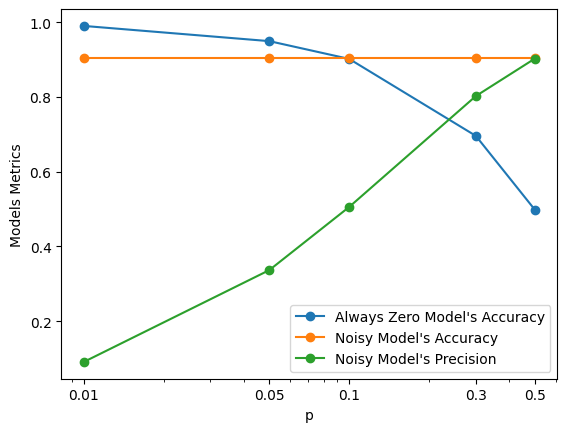

In [ ]:
import matplotlib.pyplot as plt
from pandas import DataFrame

ps = [0.5, 0.3, 0.1, 0.05, 0.01]

data_list = [{"p": p, "data": make_data(p)} for p in ps]
binary_metrics_results = [{
    "p": d["p"],
    "y_z_metrics": {k: v for k, v in
      binary_metrics(d["data"][0], d["data"][1]).items()
      if k not in ["TP", "FP", "TN", "FN"]},
    "y_n_metrics": {k: v for k, v in
      binary_metrics(d["data"][0], d["data"][2]).items()
      if k not in ["TP", "FP", "TN", "FN"]}
  } for d in data_list
]

rows = []
for item in binary_metrics_results:
  rows.append({
    "p": item["p"], "model": "zawsze-zero", **item["y_z_metrics"]
  })
  rows.append({
    "p": item["p"], "model": "zaszumiony", **item["y_n_metrics"]
  })

df = DataFrame(rows)

df_zero_model = df[df["model"] == "zawsze-zero"]
df_noisy_model = df[df["model"] == "zaszumiony"]

plt.plot(
  df_zero_model['p'],
  df_zero_model["accuracy"],
  marker="o", label="Always Zero Model's Accuracy")

plt.plot(
  df_noisy_model['p'],
  df_noisy_model["accuracy"],
  marker="o", label="Noisy Model's Accuracy")

plt.plot(
  df_noisy_model['p'],
  df_noisy_model["precision"],
  marker="o", label="Noisy Model's Precision")

plt.xscale("log")
plt.xticks(ps, ps)

plt.xlabel("p")
plt.ylabel("Models Metrics")

plt.legend()

plt.show()

In [ ]:
# TEST
assert set(df.columns) >= {"p", "model", "accuracy", "precision", "recall", "f1"}
assert len(df) == 10
z = df[(df["model"] == "zawsze-zero") & (df["p"] == 0.01)].iloc[0]
assert z["accuracy"] > 0.98 and z["recall"] == 0.0
print("D2 OK")

D2 OK


### Zadanie D3. Wnioski
Odpowiedz krótko (2–3 zdania na pytanie), odwołując się do liczb z tabeli:

1. Czy Twoje przewidywania z D1 się potwierdziły? Co Cię zaskoczyło?
2. Dla $p = 0.01$: który model ma wyższą accuracy, a który jest bardziej użyteczny? Dlaczego?
3. Model zaszumiony myli się zawsze w 10% przypadków. Dlaczego mimo to jego precision spada, gdy $p$ maleje?
4. Projektujesz system wykrywający rzadką chorobę. Którą metrykę zaraportujesz jako główną? Jakie konsekwencje dla pacjentów mają błędy FP, a jakie FN?

*Twoja odpowiedź:*

> 1. Trudno przyznawać, lecz żadne z moich przewidywań się nie potwierdziło. Zaskoczyło to,<br>
że zerowy model ma większą precyzję niż zaszumiony. Jednak pod czas rozwiązywania<br>
problemu wszystkie wątpliwości zniknęły.

> 2. Model `zawsze-zero` ma wyższą precyzję, lecz bardziej użyteczny<br>
w wykrywaniu rzadkiego zjawiska jest `zaszumiony`, ponieważ<br>
ma `recall` ~0.93, więc wykrywa około 93% rzadkich zjawisk.

> 3. Ponieważ klasa pozytywna *p* staje się rzadsza, liczba FP przewyższa TP.<br>
Dlatego `precision` spada z ~0.9 (*dla p=0,5*) do ~0.09 (*dla p=0,01*),<br>
mimo że ogólna częstość błędów pozostaje zbliżona do 10%.

> 4. a) Moim zdaniem, jeśli ***niewykrycie jak najmiejszej liczby chorych*** jest priorytetem,<br>
to raportowałbym `recall`. Dodatkowo, `precision` też jest warta uwagi,<br>
ocenia wiarygodność alarmów. <br>
b) Rozważając chorobę, jako przykład rzadkiego zjawiska, FP może powodować stres i<br>
niepotrzebne badania, natomiast FN może opóźnić diagnozę i leczenie,<br>
pogarszając stan pacjenta.



---
## Część E. Zadania dodatkowe (dla chętnych / do domu)

**E1. Pliki.** Zapisz listę wyników (po jednym w linii) do pliku `scores.txt`. Wczytaj plik, oblicz średnią i zapisz do `report.txt` raport w formacie `Wczytano N wyników, średnia: X` (X z dokładnością do 3 miejsc po przecinku).

**E2. Dane od użytkownika.** Pobierz funkcją `input()` wynik modelu `s` i wypisz:
- `Podano niepoprawną wartość!`, gdy tekstu nie da się zamienić na liczbę (`try`/`except`),
- `Wynik poza zakresem 0–1`, gdy `s < 0` lub `s > 1`,
- `Model wymaga poprawy`, gdy `s < 0.7`,
- `Wynik akceptowalny`, gdy `0.7 ≤ s < 0.85`,
- `Wynik doskonały` w pozostałych przypadkach.

**E3. Duplikaty.** Usuń duplikaty z listy `["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]` **z zachowaniem kolejności** pierwszych wystąpień. Dlaczego samo `list(set(...))` tego nie gwarantuje?

**E4. Uogólnienie.** Rozszerz `make_data` o parametr pozwalający ustawić osobno odsetek błędów dla przykładów pozytywnych i negatywnych. Jak zmienia się wykres z D2, gdy model myli się w 10% pozytywnych, ale tylko w 1% negatywnych?

In [ ]:
# E1 Pliki.

from random import random

scores_count = 1000 # dla wygody, żeby zmieniać liczbę wyników w jednym miejscu

with open("scores.txt", "w", encoding="utf-8") as scores_txt:
  for _ in range(scores_count):
     scores_txt.write(f"{random():.2f}\n")

scores_sum = 0

with open("scores.txt", "r", encoding="utf-8") as scores_txt:
  while True:
    line = scores_txt.readline()
    if not line: break

    scores_sum += float(line)

with open("raport.txt", "w", encoding="utf-8") as raport_txt:
  scores_avg = f"{(scores_sum / scores_count):.2f}"

  text = f"Wczytano {scores_count} wyników, średnia: {scores_avg}"
  raport_txt.write(text)


Wczytano 1000 wyników, średnia: 0.49


In [ ]:
# E2 Dane od użytkownika

import re

def get_user_input(msg: str) -> float:

  """
  Pobiera wartość od użytkownika, sprawdzając poprzez wyrażenie regularne
  czy dana wartość zawiera wyłącznie liczby całkowite lub zmiennoprzecinkowe
  do setnych, dodatnie i ujemne.

  (jest o)

  Args:
    msg (str): komunikat do wypisania użytkownikowi
  Returns:
    float: sprawdzona i odrazu przekonwertowana liczba zmiennoprzecinkowa
  """

  while True:
    user_input = input(msg)
    if not re.match("^-?\\d+(\\.\\d{1,2})?$", user_input):
      print("!Podano niepoprawną wartość!")
    elif not (0 <= float(user_input) <= 1):
      print("!Wynik poza zakresem 0–1!")
    else:
      return float(user_input)

s = get_user_input("Podaj wartość: ")

if s < 0.7:
  print("Model wymaga poprawy")
elif 0.7 <= s < 0.85:
  print("Wynik akceptowalny")
else:
  print("Wynik doskonały")

Podaj wartość: 0.86
Wynik doskonały


In [50]:
# E3 Duplikaty

models = ["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]

# 1. implementacja (czytelniejsza)
def remove_duplicates(models: list[str]) -> list[str]:
  """Usuwa duplikaty z listy zachowując kolejność pierwszych wystąpień.

  Nie zmienia początkowej listy.

  Jeśli `models` jest `None` lub `[]`, zwraca pustą listę.

  Args:
      models (list[str]): lista modeli

  Returns:
      list[str]: nowa lista bez duplikatów z zachowaniem kolejności
  """
  if models in [None, []]: return []

  seen = set()
  result = []
  for m in models:
    if m not in seen:
      seen.add(m)
      result.append(m)

  return result

# 2. implementacja (krótsza, być może najkrótsza)
def remove_duplicates_smaller(models: list[str]) -> list[str]:
  """To samo tylko bardziej zwięzłe i mniej czytelne

  też zachowuje kolejność (lecz tylko w PY3.7+ i PY3.6 w CPython)

  (PY 3.5 i starsze wersje nie gwarantują zachowania kolejności w tej funkcji)
  """
  return list(dict.fromkeys(models))

print(remove_duplicates(models))
print(remove_duplicates_smaller(models))


['SVM', 'NeuralNet', 'Transformer']
['SVM', 'NeuralNet', 'Transformer']
